<a href="https://colab.research.google.com/github/sp5258p/Organic-Farming-Suitability-Prediction/blob/main/Organic_Farming_Suitability_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# CELL 1  — IMPORT LIBRARIES
import warnings, os, joblib
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    balanced_accuracy_score, matthews_corrcoef)
sns.set_theme(style='whitegrid', context='notebook')
SEED = 42
print('Libraries imported successfully ')

Libraries imported successfully 


In [ ]:
# CELL 2 — SET DATASET PATH
DATA_PATH ="C://Users//ashiq//Downloads//organic_farming_suitability_1000_source_calibrated.csv"
print('Dataset path:', DATA_PATH)

Dataset path: C://Users//ashiq//Downloads//organic_farming_suitability_1000_source_calibrated.csv


In [ ]:
# CELL 3 — LOAD CSV
df = pd.read_csv(DATA_PATH)
print('Dataset loaded successfully!')
print('Rows:', df.shape[0], '| Columns:', df.shape[1])

Dataset loaded successfully!
Rows: 1000 | Columns: 24


In [ ]:
# CELL 4 — DISPLAY FIRST 10 RECORDS
display(df.head(10))

,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,...,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
0,OF-0001,Haryana,Sandy,Tomato,6.13,0.411,80.0,65.2,266.9,15.71,...,0.29,0.191,954.2,26.5,17.9,Mixed,Low,0,39.1,Not Suitable
1,OF-0002,Andhra Pradesh,Loamy,Sugarcane,7.58,0.826,187.8,29.4,131.5,13.64,...,0.65,0.652,841.9,30.7,33.6,Chemical,Moderate,8,53.0,Not Suitable
2,OF-0003,Karnataka,Loamy,Pulses,6.00,0.684,353.4,3.0,351.5,20.35,...,0.48,0.317,562.3,23.0,30.6,Chemical,Moderate,12,45.2,Not Suitable
3,OF-0004,Madhya Pradesh,Red,Pulses,6.69,0.706,200.3,39.0,61.7,10.96,...,2.51,0.323,741.1,26.8,33.5,Chemical,Moderate,8,44.7,Not Suitable
4,OF-0005,Madhya Pradesh,Red,Sugarcane,6.46,1.564,181.3,11.7,411.4,14.66,...,0.65,0.512,870.0,25.0,24.3,Chemical,High,2,52.6,Not Suitable
5,OF-0006,Telangana,Loamy,Soybean,7.02,0.367,384.4,16.1,196.8,3.00,...,0.45,0.242,1311.8,22.7,27.5,Mixed,High,6,44.6,Not Suitable
6,OF-0007,Haryana,Black,Groundnut,6.42,0.642,387.3,39.3,67.7,28.06,...,0.30,0.271,1180.0,26.8,8.4,Chemical,Low,15,59.9,Suitable
7,OF-0008,Tamil Nadu,Loamy,Chickpea,6.70,0.745,309.1,32.6,457.3,14.46,...,1.15,0.414,1771.5,33.1,31.4,Mixed,Low,4,67.0,Suitable
8,OF-0009,Bihar,Red,Groundnut,6.72,0.467,216.8,19.2,241.2,19.19,...,0.50,0.150,1253.5,24.0,28.9,Chemical,Low,10,42.9,Not Suitable
9,OF-0010,Haryana,Alluvial,Tomato,6.35,0.658,237.3,16.3,498.0,26.20,...,0.40,0.395,1140.9,26.6,18.1,Chemical,Moderate,10,48.5,Not Suitable


In [ ]:
# CELL 5  — DISPLAY LAST 5 RECORDS
display(df.tail())

,Sample_ID,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,...,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input,Suitability_Score,Organic_Farming_Suitability
995,OF-0996,Karnataka,Laterite,Soybean,6.02,0.469,367.3,3.0,472.3,6.01,...,0.48,0.671,1260.1,26.7,25.6,Mixed,Moderate,0,43.7,Not Suitable
996,OF-0997,Rajasthan,Loamy,Rice,7.47,1.900,181.2,40.5,490.6,27.51,...,0.49,1.059,504.7,32.9,41.9,Chemical,Moderate,4,81.6,Suitable
997,OF-0998,Maharashtra,Laterite,Potato,6.68,0.631,252.6,3.0,373.7,15.84,...,0.41,0.450,789.1,25.7,32.2,Organic,High,1,46.4,Not Suitable
998,OF-0999,Assam,Black,Sugarcane,5.01,0.541,86.9,35.7,341.8,18.22,...,0.78,0.239,704.7,24.5,16.4,Chemical,Moderate,7,20.3,Not Suitable
999,OF-1000,Rajasthan,Laterite,Mustard,5.30,0.658,366.7,24.3,223.3,13.23,...,0.40,0.500,1314.0,25.4,37.9,Mixed,Moderate,3,22.6,Not Suitable


In [ ]:
# CELL 6 — SHAPE AND DIMENSIONS
print(f'Rows: {df.shape[0]}')
print(f'Columns: {df.shape[1]}')
print(f'Total cells: {df.size:,}')

Rows: 1000
Columns: 24
Total cells: 24,000


In [ ]:
# CELL 7  — COLUMN NAMES
for i, col in enumerate(df.columns, start=1):
    print(f'{i:02d}. {col}')

01. Sample_ID
02. State
03. Soil_Type
04. Crop
05. pH
06. Organic_Carbon_pct
07. Available_N_kg_ha
08. Available_P_kg_ha
09. Available_K_kg_ha
10. Available_S_mg_kg
11. Available_Zn_mg_kg
12. Available_Fe_mg_kg
13. Available_Mn_mg_kg
14. Available_Cu_mg_kg
15. Available_B_mg_kg
16. EC_dS_m
17. Annual_Rainfall_mm
18. Mean_Temperature_C
19. Soil_Moisture_pct
20. Previous_Fertilizer_Usage
21. Previous_Pesticide_Usage
22. Years_Chemical_Input
23. Suitability_Score
24. Organic_Farming_Suitability


In [ ]:
# CELL 8  — DATA TYPES
display(df.dtypes.to_frame('Data Type'))

,Data Type
Sample_ID,object
State,object
Soil_Type,object
Crop,object
pH,float64
Organic_Carbon_pct,float64
Available_N_kg_ha,float64
Available_P_kg_ha,float64
Available_K_kg_ha,float64
Available_S_mg_kg,float64


In [ ]:
# CELL 9 — DATAFRAME INFO
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Sample_ID                    1000 non-null   object 
 1   State                        1000 non-null   object 
 2   Soil_Type                    1000 non-null   object 
 3   Crop                         1000 non-null   object 
 4   pH                           1000 non-null   float64
 5   Organic_Carbon_pct           1000 non-null   float64
 6   Available_N_kg_ha            1000 non-null   float64
 7   Available_P_kg_ha            1000 non-null   float64
 8   Available_K_kg_ha            1000 non-null   float64
 9   Available_S_mg_kg            1000 non-null   float64
 10  Available_Zn_mg_kg           1000 non-null   float64
 11  Available_Fe_mg_kg           1000 non-null   float64
 12  Available_Mn_mg_kg           1000 non-null   float64
 13  Available_Cu_mg_kg 

In [ ]:
# CELL 10— NUMERICAL STATISTICAL SUMMARY
display(df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
pH,1000.0,6.92,0.75,4.80,6.40,6.92,7.42,9.19
Organic_Carbon_pct,1000.0,0.72,0.35,0.19,0.48,0.65,0.88,2.50
Available_N_kg_ha,1000.0,259.02,91.35,80.00,194.08,257.30,315.82,588.10
Available_P_kg_ha,1000.0,29.55,16.86,3.00,16.48,29.10,40.82,86.30
Available_K_kg_ha,1000.0,254.25,126.80,40.00,165.70,242.35,345.92,653.20
Available_S_mg_kg,1000.0,15.80,6.62,3.00,11.28,15.54,20.26,39.06
Available_Zn_mg_kg,1000.0,0.79,0.37,0.15,0.53,0.71,0.96,4.00
Available_Fe_mg_kg,1000.0,20.48,12.80,2.99,11.92,17.34,25.31,80.00
Available_Mn_mg_kg,1000.0,9.19,5.36,1.44,5.49,7.76,11.62,40.00
Available_Cu_mg_kg,1000.0,0.77,0.39,0.17,0.52,0.70,0.93,4.00


In [ ]:
# CELL 11— SUMMARY INCLUDING CATEGORICAL FEATURES
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Sample_ID,1000,1000,OF-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,1000,15,Madhya Pradesh,81,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Soil_Type,1000,7,Alluvial,279,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Crop,1000,12,Maize,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pH,1000.0,NaN,NaN,NaN,6.91594,0.754045,4.8,6.4,6.925,7.42,9.19
Organic_Carbon_pct,1000.0,NaN,NaN,NaN,0.724501,0.346696,0.189,0.481,0.6535,0.87725,2.5
Available_N_kg_ha,1000.0,NaN,NaN,NaN,259.0167,91.347824,80.0,194.075,257.3,315.825,588.1
Available_P_kg_ha,1000.0,NaN,NaN,NaN,29.5494,16.859065,3.0,16.475,29.1,40.825,86.3
Available_K_kg_ha,1000.0,NaN,NaN,NaN,254.2527,126.79943,40.0,165.7,242.35,345.925,653.2
Available_S_mg_kg,1000.0,NaN,NaN,NaN,15.80129,6.615834,3.0,11.2825,15.54,20.2575,39.06


In [ ]:
# CELL 12  — CLEAN COLUMN NAMES
df.columns = df.columns.str.strip()
print('Column whitespace cleaned.')

Column whitespace cleaned.


In [ ]:
# CELL 13— MISSING VALUE COUNTS
missing_counts = df.isna().sum().sort_values(ascending=False)
display(missing_counts.to_frame('Missing Count'))

,Missing Count
Sample_ID,0
State,0
Suitability_Score,0
Years_Chemical_Input,0
Previous_Pesticide_Usage,0
Previous_Fertilizer_Usage,0
Soil_Moisture_pct,0
Mean_Temperature_C,0
Annual_Rainfall_mm,0
EC_dS_m,0


In [ ]:
# CELL 14 — MISSING VALUE PERCENTAGE
missing_percent = (df.isna().mean()*100).round(2)
display(pd.DataFrame({'Missing Count':df.isna().sum(), 'Missing %':missing_percent}).sort_values('Missing %',ascending=False))

,Missing Count,Missing %
Sample_ID,0,0.0
State,0,0.0
Suitability_Score,0,0.0
Years_Chemical_Input,0,0.0
Previous_Pesticide_Usage,0,0.0
Previous_Fertilizer_Usage,0,0.0
Soil_Moisture_pct,0,0.0
Mean_Temperature_C,0,0.0
Annual_Rainfall_mm,0,0.0
EC_dS_m,0,0.0


In [ ]:
# CELL 15  — DUPLICATE ROW CHECK
print('Duplicate full rows:', df.duplicated().sum())

Duplicate full rows: 0


In [ ]:
# CELL 16 — DUPLICATE SAMPLE ID CHECK
if 'Sample_ID' in df.columns:
    print('Duplicated Sample_ID:', df['Sample_ID'].duplicated().sum())
else:
    print('Sample_ID column is absent.')

Duplicated Sample_ID: 0


In [ ]:
# CELL 17  — REMOVE FULL ROW DUPLICATES
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print('Rows removed:', before-len(df))
print('Updated shape:', df.shape)

Rows removed: 0
Updated shape: (1000, 24)


In [ ]:
# CELL 18  — HANDLE INFINITY VALUES
numeric_for_inf = df.select_dtypes(include=np.number).columns
inf_count = np.isinf(df[numeric_for_inf]).sum().sum()
print('Infinite numeric values:', int(inf_count))
df = df.replace([np.inf,-np.inf], np.nan)

Infinite numeric values: 0


In [ ]:
# CELL 19  — TARGET LABELS AND COUNTS
TARGET = 'Organic_Farming_Suitability'
print('Target classes:', df[TARGET].unique())
display(df[TARGET].value_counts().to_frame('Records'))

Target classes: ['Not Suitable' 'Suitable']


,Records
Organic_Farming_Suitability,
Not Suitable,577
Suitable,423


In [ ]:
# CELL 20 — TARGET CLASS PERCENTAGES
target_pct = df[TARGET].value_counts(normalize=True).mul(100).round(2)
display(target_pct.to_frame('Percentage (%)'))

,Percentage (%)
Organic_Farming_Suitability,
Not Suitable,57.7
Suitable,42.3


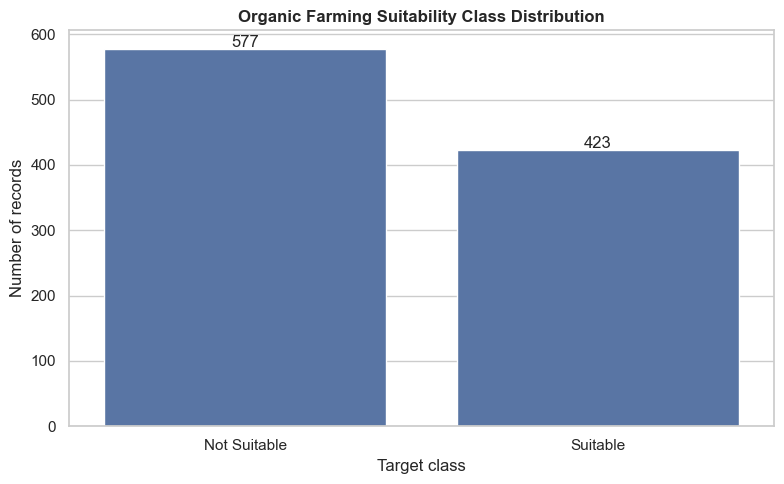

In [ ]:
# CELL 21 — CLASS BALANCE BAR PLOT
counts = df[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(8,5))
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set_title('Organic Farming Suitability Class Distribution', weight='bold')
ax.set_xlabel('Target class');
ax.set_ylabel('Number of records')
for i,v in enumerate(counts.values):
    ax.text(i,v+3,str(v),ha='center')
plt.tight_layout();
plt.show()

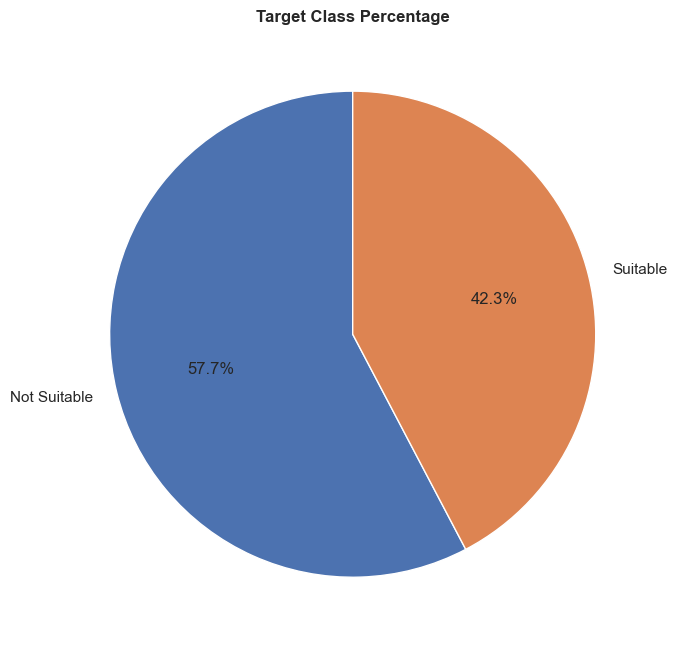

In [ ]:
# CELL 22 — CLASS DISTRIBUTION PIE CHART
plt.figure(figsize=(7,7))
plt.pie(counts.values, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Target Class Percentage', weight='bold');
plt.tight_layout();
plt.show()

In [ ]:
# CELL 23  — NUMERICAL FEATURE LIST
num_cols = df.select_dtypes(include=np.number).columns.tolist()
print('Numerical columns:', num_cols)

Numerical columns: ['pH', 'Organic_Carbon_pct', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Available_S_mg_kg', 'Available_Zn_mg_kg', 'Available_Fe_mg_kg', 'Available_Mn_mg_kg', 'Available_Cu_mg_kg', 'Available_B_mg_kg', 'EC_dS_m', 'Annual_Rainfall_mm', 'Mean_Temperature_C', 'Soil_Moisture_pct', 'Years_Chemical_Input', 'Suitability_Score']


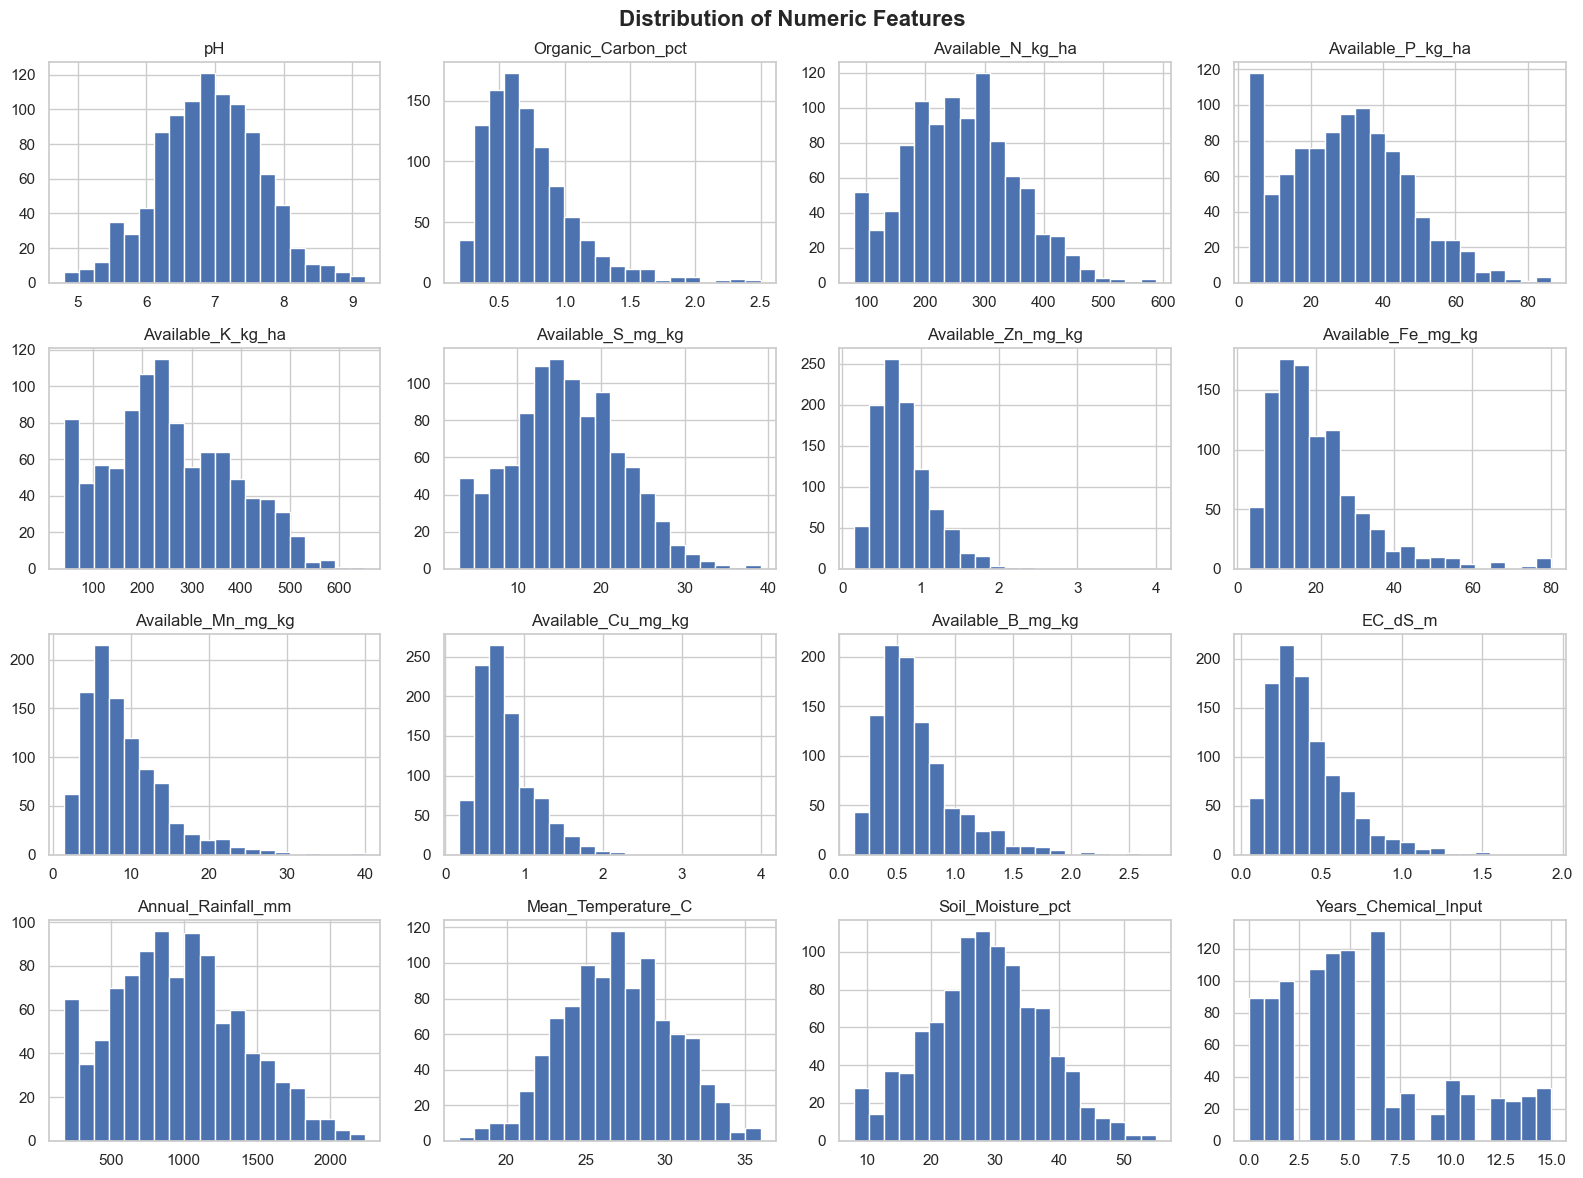

In [ ]:
# CELL 24 — NUMERIC HISTOGRAM GRID
plot_cols = [c for c in num_cols if c not in ['Sample_ID','Suitability_Score']]
if plot_cols:
    df[plot_cols].hist(figsize=(16,12), bins=20, edgecolor='white')
    plt.suptitle('Distribution of Numeric Features', fontsize=16, weight='bold')
    plt.tight_layout();
    plt.show()

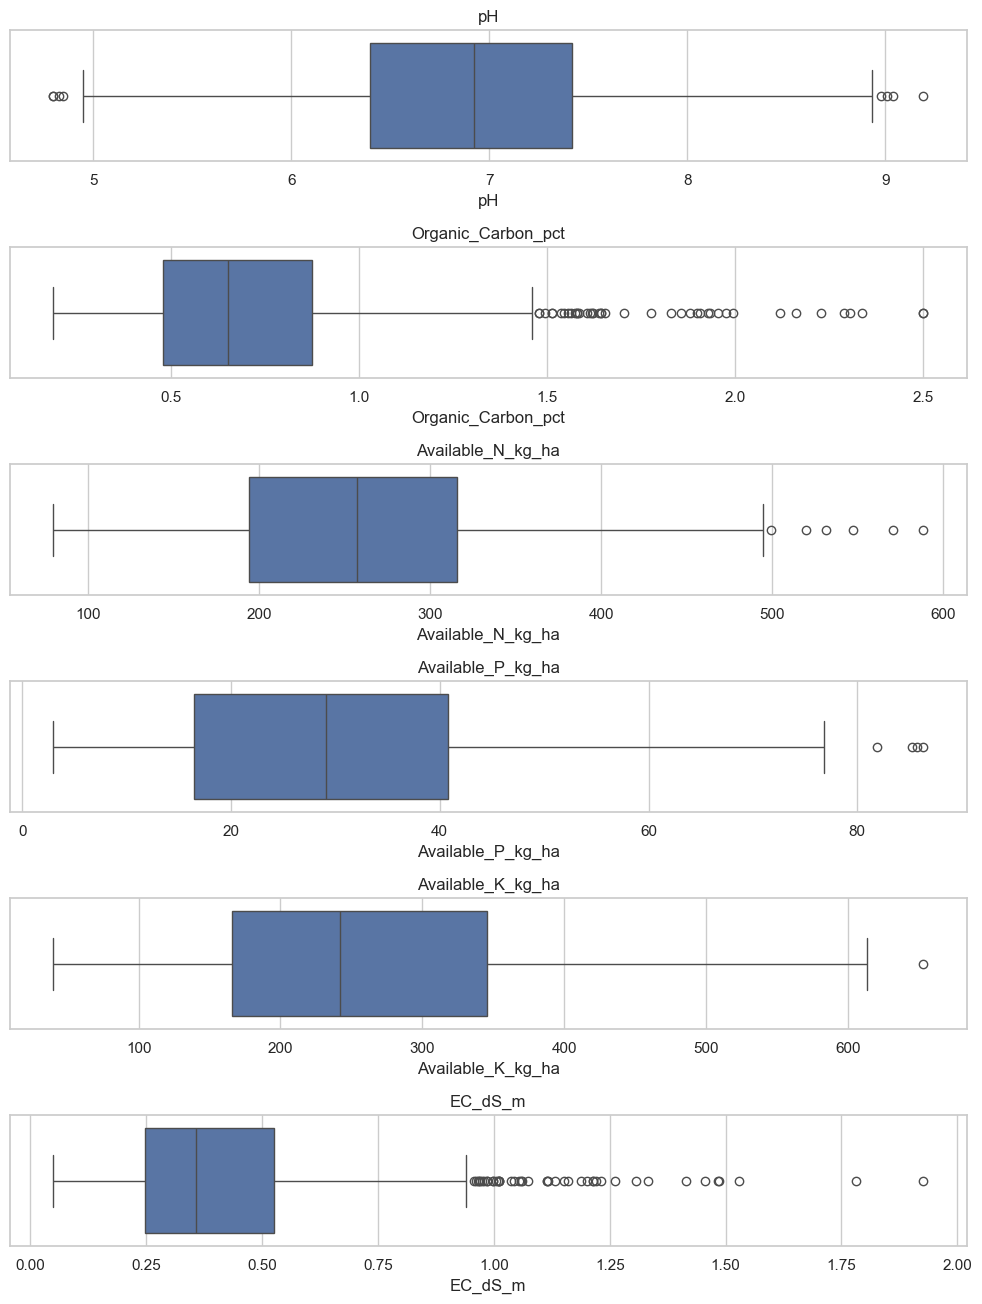

In [ ]:
# CELL 25  — BOX PLOTS FOR SELECTED SOIL FEATURES
box_cols = [c for c in ['pH','Organic_Carbon_pct','Available_N_kg_ha','Available_P_kg_ha','Available_K_kg_ha','EC_dS_m'] if c in df.columns]
fig, axes = plt.subplots(len(box_cols),1,figsize=(10,max(3,len(box_cols)*2.2)))
if len(box_cols)==1: axes=[axes]
for ax,col in zip(axes,box_cols):
    sns.boxplot(x=df[col],ax=ax);
    ax.set_title(col)
plt.tight_layout();
plt.show()

In [ ]:
# CELL 26 — CATEGORICAL COLUMN LIST
cat_cols = df.select_dtypes(exclude=np.number).columns.tolist()
print('Categorical columns:', cat_cols)

Categorical columns: ['Sample_ID', 'State', 'Soil_Type', 'Crop', 'Previous_Fertilizer_Usage', 'Previous_Pesticide_Usage', 'Organic_Farming_Suitability']


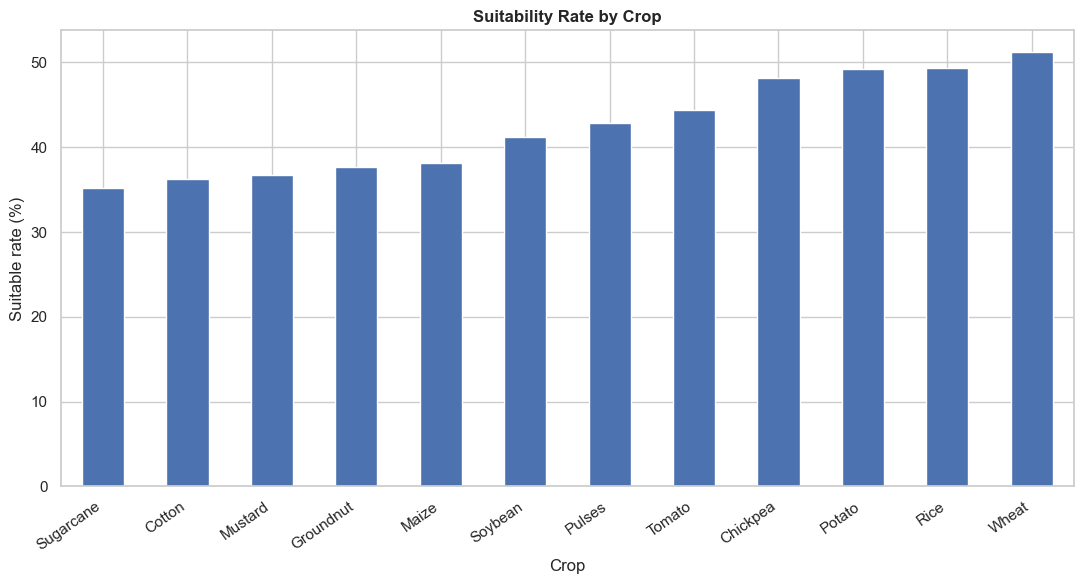

In [ ]:
# CELL 27  — SUITABILITY RATE BY CROP
if 'Crop' in df.columns:
    rates = df.groupby('Crop')[TARGET].apply(lambda s:(s=='Suitable').mean()*100).sort_values()
    plt.figure(figsize=(11,6));
    rates.plot(kind='bar')
    plt.ylabel('Suitable rate (%)');
    plt.title('Suitability Rate by Crop',weight='bold')
    plt.xticks(rotation=35,ha='right');
    plt.tight_layout();
    plt.show()

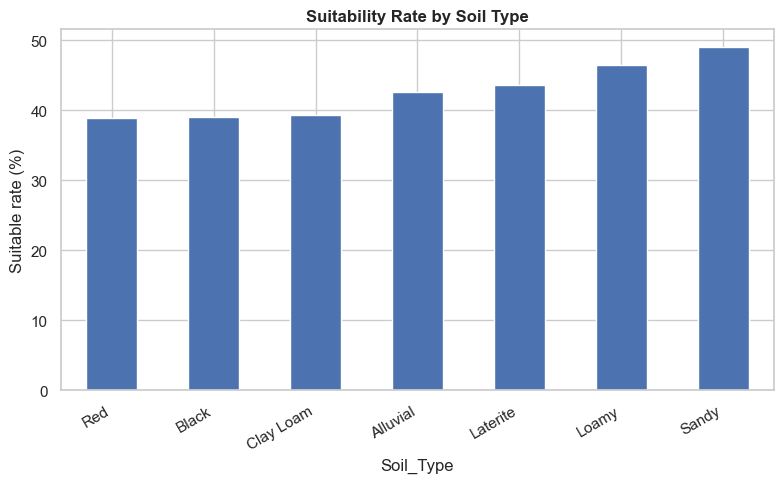

In [ ]:
# CELL 28 — SUITABILITY RATE BY SOIL TYPE
if 'Soil_Type' in df.columns:
    rates_soil = df.groupby('Soil_Type')[TARGET].apply(lambda s:(s=='Suitable').mean()*100).sort_values()
    plt.figure(figsize=(8,5));
    rates_soil.plot(kind='bar')
    plt.ylabel('Suitable rate (%)');
    plt.title('Suitability Rate by Soil Type',weight='bold')
    plt.xticks(rotation=30,ha='right');
    plt.tight_layout();
    plt.show()

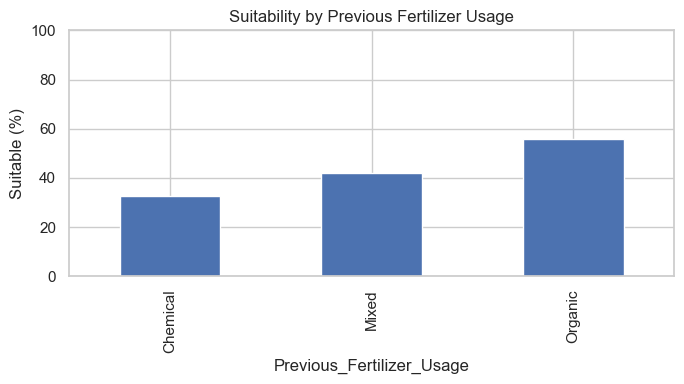

In [ ]:
# CELL 29  — SUITABILITY RATE BY PREVIOUS FERTILIZER
col='Previous_Fertilizer_Usage'
if col in df.columns:
    rate=df.groupby(col)[TARGET].apply(lambda s:(s=='Suitable').mean()*100)
    plt.figure(figsize=(7,4));
    rate.plot(kind='bar')
    plt.title('Suitability by Previous Fertilizer Usage');
    plt.ylabel('Suitable (%)')
    plt.ylim(0,100);
    plt.tight_layout();
    plt.show()

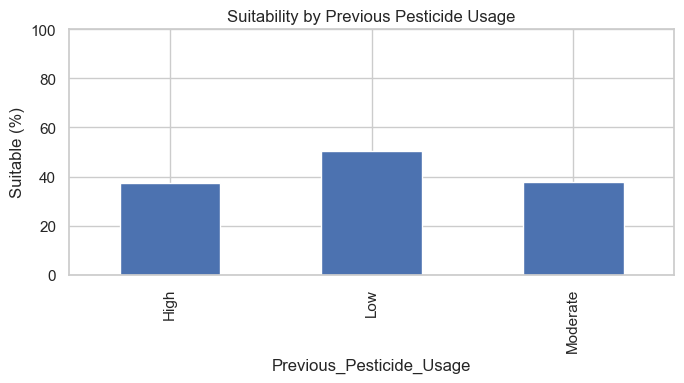

In [ ]:
# CELL 30 OF 40 — SUITABILITY RATE BY PESTICIDE USAGE
col='Previous_Pesticide_Usage'
if col in df.columns:
    rate=df.groupby(col)[TARGET].apply(lambda s:(s=='Suitable').mean()*100)
    plt.figure(figsize=(7,4));
    rate.plot(kind='bar')
    plt.title('Suitability by Previous Pesticide Usage');
    plt.ylabel('Suitable (%)')
    plt.ylim(0,100);
    plt.tight_layout();
    plt.show()

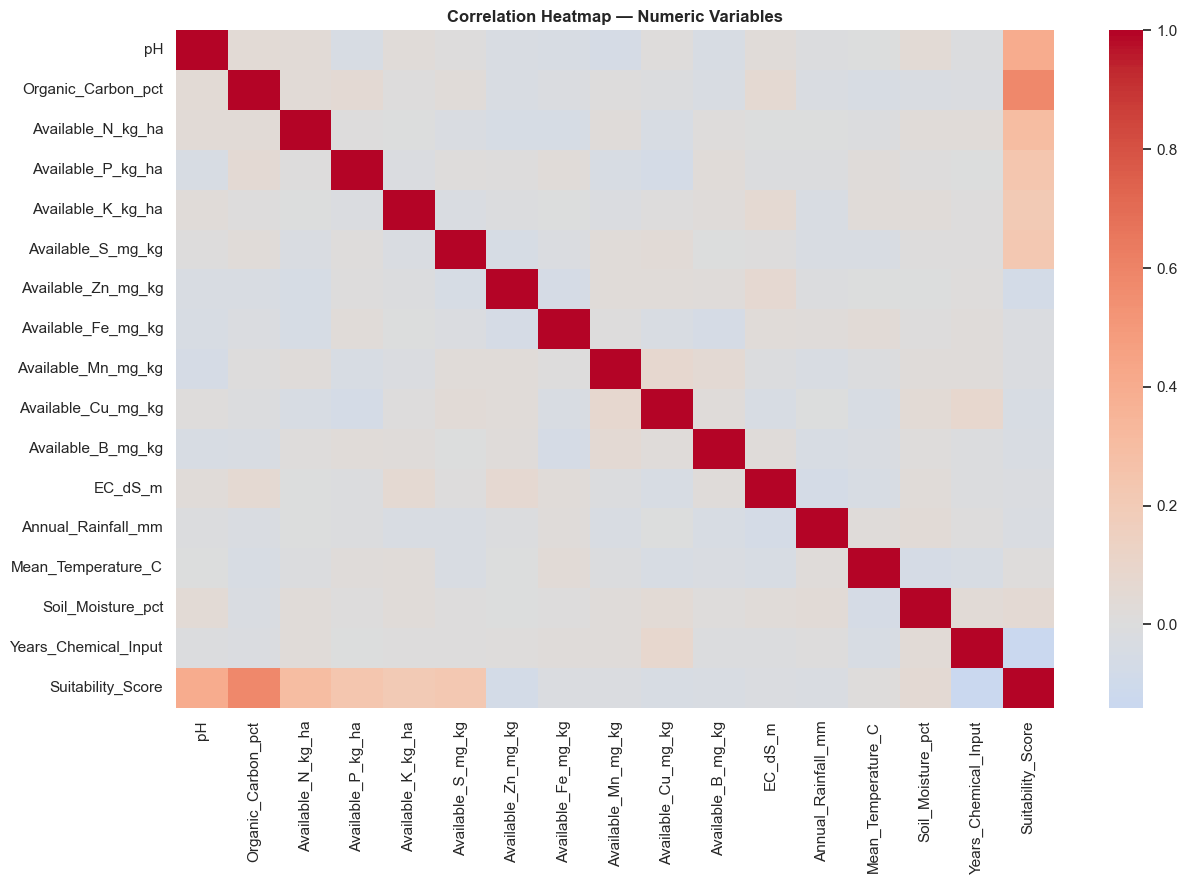

In [ ]:
# CELL 31  — CORRELATION HEATMAP
correlation_cols=[c for c in num_cols if c not in ['Sample_ID']]
correlation=df[correlation_cols].corr(numeric_only=True)
plt.figure(figsize=(13,9));
sns.heatmap(correlation,cmap='coolwarm',center=0,annot=False)
plt.title('Correlation Heatmap — Numeric Variables',weight='bold')
plt.tight_layout();
plt.show()

In [ ]:
# CELL 32  — DEFINE TARGET AND FEATURES
exclude_cols=['Sample_ID','Suitability_Score',TARGET]
X=df.drop(columns=[c for c in exclude_cols if c in df.columns])
y=df[TARGET].astype(str)
print('X shape:',X.shape,'| y shape:',y.shape)
display(X.head())

X shape: (1000, 21) | y shape: (1000,)


,State,Soil_Type,Crop,pH,Organic_Carbon_pct,Available_N_kg_ha,Available_P_kg_ha,Available_K_kg_ha,Available_S_mg_kg,Available_Zn_mg_kg,...,Available_Mn_mg_kg,Available_Cu_mg_kg,Available_B_mg_kg,EC_dS_m,Annual_Rainfall_mm,Mean_Temperature_C,Soil_Moisture_pct,Previous_Fertilizer_Usage,Previous_Pesticide_Usage,Years_Chemical_Input
0,Haryana,Sandy,Tomato,6.13,0.411,80.0,65.2,266.9,15.71,0.33,...,20.76,1.43,0.29,0.191,954.2,26.5,17.9,Mixed,Low,0
1,Andhra Pradesh,Loamy,Sugarcane,7.58,0.826,187.8,29.4,131.5,13.64,0.66,...,11.35,0.71,0.65,0.652,841.9,30.7,33.6,Chemical,Moderate,8
2,Karnataka,Loamy,Pulses,6.00,0.684,353.4,3.0,351.5,20.35,0.81,...,30.98,0.72,0.48,0.317,562.3,23.0,30.6,Chemical,Moderate,12
3,Madhya Pradesh,Red,Pulses,6.69,0.706,200.3,39.0,61.7,10.96,0.95,...,5.20,0.73,2.51,0.323,741.1,26.8,33.5,Chemical,Moderate,8
4,Madhya Pradesh,Red,Sugarcane,6.46,1.564,181.3,11.7,411.4,14.66,0.64,...,3.03,0.72,0.65,0.512,870.0,25.0,24.3,Chemical,High,2


In [ ]:
# CELL 33  — IDENTIFY NUMERIC AND CATEGORICAL PREDICTORS
numeric_features=X.select_dtypes(include=np.number).columns.tolist()
categorical_features=X.select_dtypes(exclude=np.number).columns.tolist()
print('Numeric features:',numeric_features)
print('Categorical features:',categorical_features)

Numeric features: ['pH', 'Organic_Carbon_pct', 'Available_N_kg_ha', 'Available_P_kg_ha', 'Available_K_kg_ha', 'Available_S_mg_kg', 'Available_Zn_mg_kg', 'Available_Fe_mg_kg', 'Available_Mn_mg_kg', 'Available_Cu_mg_kg', 'Available_B_mg_kg', 'EC_dS_m', 'Annual_Rainfall_mm', 'Mean_Temperature_C', 'Soil_Moisture_pct', 'Years_Chemical_Input']
Categorical features: ['State', 'Soil_Type', 'Crop', 'Previous_Fertilizer_Usage', 'Previous_Pesticide_Usage']


In [ ]:
# CELL 34  — TRAIN TEST SPLIT
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=SEED,stratify=y)
print('Training size:',X_train.shape[0])
print('Testing size:',X_test.shape[0])

Training size: 800
Testing size: 200


In [ ]:
# CELL 35 OF 40 — PREPROCESSING PIPELINES
def build_preprocessor(scale_numeric=True):
    numeric_pipe=Pipeline([('imputer',SimpleImputer(strategy='median'))])
    if scale_numeric: numeric_pipe.steps.append(('scaler',StandardScaler()))
    categorical_pipe=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))])
    return ColumnTransformer([('numeric',numeric_pipe,numeric_features),('categorical',categorical_pipe,categorical_features)])
print('Preprocessor builder ready.')

Preprocessor builder ready.


In [ ]:
# CELL 36  — DEFINE FOUR CLASSIFICATION MODELS
models={
 'Logistic Regression':Pipeline([('prep',build_preprocessor(True)),('model',LogisticRegression(max_iter=3000,random_state=SEED))]),
 'Decision Tree':Pipeline([('prep',build_preprocessor(False)),('model',DecisionTreeClassifier(max_depth=7,min_samples_leaf=4,random_state=SEED))]),
 'K-Nearest Neighbors':Pipeline([('prep',build_preprocessor(True)),('model',KNeighborsClassifier(n_neighbors=7))]),
 'Random Forest':Pipeline([('prep',build_preprocessor(False)),('model',RandomForestClassifier(n_estimators=300,min_samples_leaf=2,class_weight='balanced',random_state=SEED,n_jobs=-1))])
}
print('Models:',list(models.keys()))

Models: ['Logistic Regression', 'Decision Tree', 'K-Nearest Neighbors', 'Random Forest']


In [ ]:
# CELL 37  — 5-FOLD CROSS-VALIDATION MODEL COMPARISON
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
scoring={'accuracy':'accuracy','precision':'precision_weighted','recall':'recall_weighted','f1':'f1_weighted'}
comparison=[]
for name,pipe in models.items():
    scores=cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
    comparison.append({'Model':name,'CV Accuracy':scores['test_accuracy'].mean(),'CV Precision':scores['test_precision'].mean(),'CV Recall':scores['test_recall'].mean(),'CV F1':scores['test_f1'].mean(),'F1 Std':scores['test_f1'].std()})
results=pd.DataFrame(comparison).sort_values('CV F1',ascending=False).reset_index(drop=True)
display(results.style.format({c:'{:.3f}' for c in results.columns if c!='Model'}))

,Model,CV Accuracy,CV Precision,CV Recall,CV F1,F1 Std
0,Logistic Regression,0.835,0.835,0.835,0.834,0.017
1,Random Forest,0.825,0.828,0.825,0.822,0.013
2,K-Nearest Neighbors,0.763,0.761,0.763,0.761,0.031
3,Decision Tree,0.724,0.723,0.724,0.722,0.043


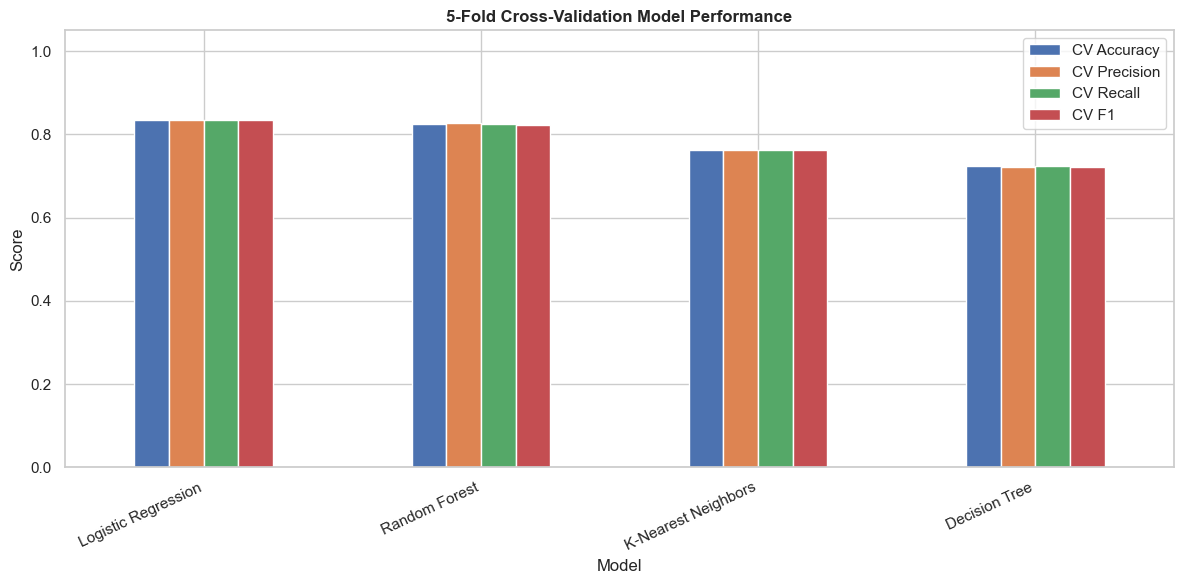

Selected model based on CV weighted F1: Logistic Regression


In [ ]:
# CELL 38  — MODEL COMPARISON VISUALIZATION AND BEST MODEL
results.set_index('Model')[['CV Accuracy','CV Precision','CV Recall','CV F1']].plot(kind='bar',figsize=(12,6))
plt.title('5-Fold Cross-Validation Model Performance',weight='bold'); plt.ylabel('Score'); plt.ylim(0,1.05)
plt.xticks(rotation=25,ha='right');
plt.tight_layout();
plt.show()
best_name=results.loc[0,'Model']; best_model=models[best_name]
print('Selected model based on CV weighted F1:',best_name)

              precision    recall  f1-score   support

Not Suitable       0.82      0.85      0.83       115
    Suitable       0.79      0.74      0.76        85

    accuracy                           0.81       200
   macro avg       0.80      0.80      0.80       200
weighted avg       0.80      0.81      0.80       200



,Test Score
Accuracy,0.805
Balanced Accuracy,0.797
Precision Weighted,0.804
Recall Weighted,0.805
F1 Weighted,0.804
MCC,0.599


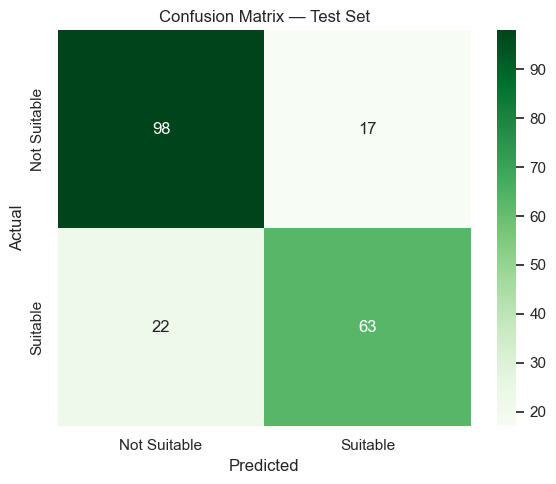

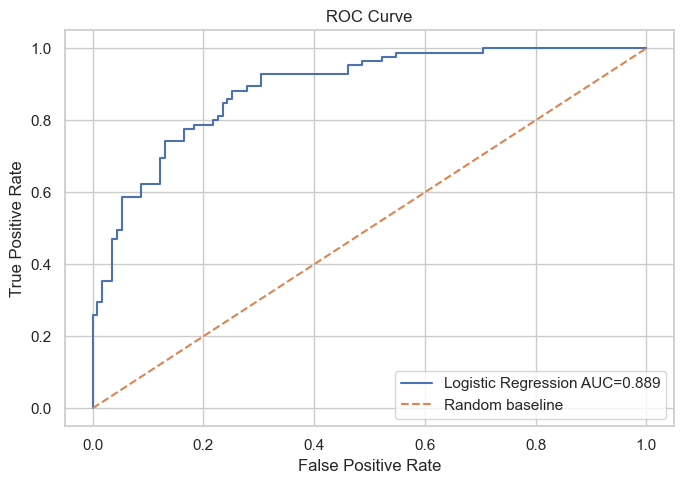

In [ ]:
# CELL 39 — FINAL TEST EVALUATION, CONFUSION MATRIX, ROC, IMPORTANCE
best_model.fit(X_train,y_train)
y_pred=best_model.predict(X_test)
print(classification_report(y_test,y_pred,zero_division=0))
metric_summary={'Accuracy':accuracy_score(y_test,y_pred),'Balanced Accuracy':balanced_accuracy_score(y_test,y_pred),'Precision Weighted':precision_score(y_test,y_pred,average='weighted',zero_division=0),'Recall Weighted':recall_score(y_test,y_pred,average='weighted',zero_division=0),'F1 Weighted':f1_score(y_test,y_pred,average='weighted',zero_division=0),'MCC':matthews_corrcoef(y_test,y_pred)}
display(pd.Series(metric_summary,name='Test Score').to_frame().style.format('{:.3f}'))
cm=confusion_matrix(y_test,y_pred,labels=['Not Suitable','Suitable'])
plt.figure(figsize=(6,5));
sns.heatmap(cm,annot=True,fmt='d',cmap='Greens',xticklabels=['Not Suitable','Suitable'],yticklabels=['Not Suitable','Suitable'])
plt.xlabel('Predicted');
plt.ylabel('Actual');
plt.title('Confusion Matrix — Test Set');
plt.tight_layout();
plt.show()

classes=list(best_model.classes_); suitable_idx=classes.index('Suitable')
probs=best_model.predict_proba(X_test)[:,suitable_idx]
roc_y=(y_test=='Suitable').astype(int); auc=roc_auc_score(roc_y,probs)
fpr,tpr,_=roc_curve(roc_y,probs)
plt.figure(figsize=(7,5));
plt.plot(fpr,tpr,label=f'{best_name} AUC={auc:.3f}'); plt.plot([0,1],[0,1],'--',label='Random baseline')
plt.xlabel('False Positive Rate');
plt.ylabel('True Positive Rate');
plt.title('ROC Curve');
plt.legend();
plt.tight_layout();
plt.show()



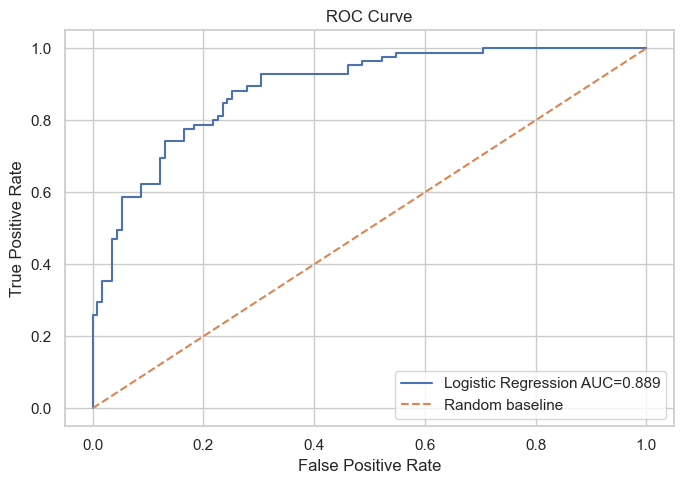

In [ ]:
classes=list(best_model.classes_); suitable_idx=classes.index('Suitable')
probs=best_model.predict_proba(X_test)[:,suitable_idx]
roc_y=(y_test=='Suitable').astype(int); auc=roc_auc_score(roc_y,probs)
fpr,tpr,_=roc_curve(roc_y,probs)
plt.figure(figsize=(7,5));
plt.plot(fpr,tpr,label=f'{best_name} AUC={auc:.3f}'); plt.plot([0,1],[0,1],'--',label='Random baseline')
plt.xlabel('False Positive Rate');
plt.ylabel('True Positive Rate');
plt.title('ROC Curve');
plt.legend();
plt.tight_layout();
plt.show()

ROC-AUC: 0.889


,Feature,Importance
1,numeric__Organic_Carbon_pct,2.724125
2,numeric__Available_N_kg_ha,1.240699
0,numeric__pH,1.236233
50,categorical__Previous_Fertilizer_Usage_Chemical,1.225090
54,categorical__Previous_Pesticide_Usage_Low,1.056067
53,categorical__Previous_Pesticide_Usage_High,1.038983
52,categorical__Previous_Fertilizer_Usage_Organic,1.025551
37,categorical__Soil_Type_Sandy,1.014842
3,numeric__Available_P_kg_ha,0.842561
5,numeric__Available_S_mg_kg,0.696417


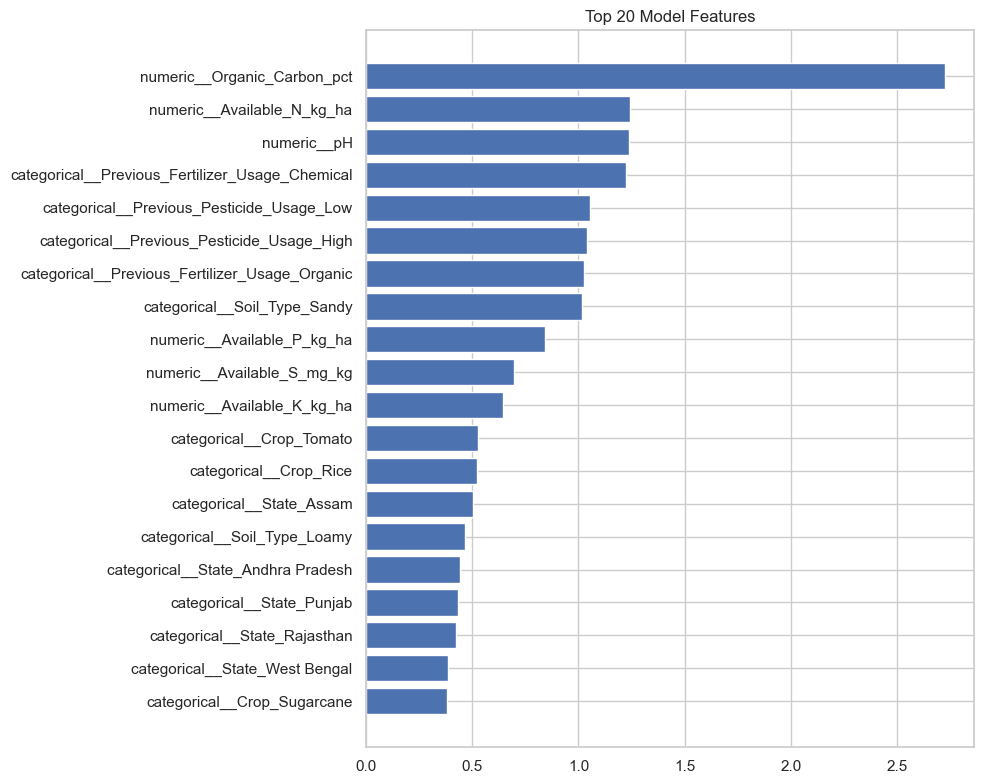

In [ ]:
print('ROC-AUC:',round(auc,3))
model_est=best_model.named_steps['model']; feature_names=best_model.named_steps['prep'].get_feature_names_out()
if hasattr(model_est,'feature_importances_'):
    imp=model_est.feature_importances_
elif hasattr(model_est,'coef_'):
    imp=np.mean(np.abs(model_est.coef_),axis=0)
else:
    imp=None
if imp is not None:
    importance_df=pd.DataFrame({'Feature':feature_names,'Importance':imp}).sort_values('Importance',ascending=False)
    display(importance_df.head(20))
    top=importance_df.head(20).sort_values('Importance')
    plt.figure(figsize=(10,8));
    plt.barh(top.Feature,top.Importance);
    plt.title('Top 20 Model Features');
    plt.tight_layout();
    plt.show()

In [ ]:
# CELL 40 OF 40 — DEMO PREDICTION, EXPORT MODEL & FINAL SUMMARY
sample_input=X_test.iloc[[0]].copy()
sample_prediction=best_model.predict(sample_input)[0]
sample_prob=best_model.predict_proba(sample_input)[0]
print('Demo input:'); display(sample_input.T)
print('Predicted suitability:',sample_prediction)
display(pd.DataFrame({'Class':best_model.classes_,'Probability':sample_prob}).sort_values('Probability',ascending=False).style.format({'Probability':'{:.2%}'}))
# Fit final deployment pipeline on all records after test evaluation is complete
final_model=models[best_name]
final_model.fit(X,y)
joblib.dump({'model':final_model,'model_name':best_name,'feature_columns':X.columns.tolist(),'dataset_note':'Source-calibrated synthetic educational dataset'},'organic_farming_best_model.joblib')
print('Model saved as organic_farming_best_model.joblib')
final_summary=pd.DataFrame({'Item':['Dataset records','Predictor count','Target','Best CV model','Test Accuracy','Test F1 Weighted','Test ROC-AUC','Dataset type'],'Result':[len(df),X.shape[1],TARGET,best_name,f'{metric_summary["Accuracy"]:.3f}',f'{metric_summary["F1 Weighted"]:.3f}',f'{auc:.3f}','Synthetic educational dataset']})
display(final_summary)
print('Reminder: This is an educational demonstration, not field validation, certification, or professional farming advice.')

Demo input:


,484
State,Madhya Pradesh
Soil_Type,Alluvial
Crop,Soybean
pH,6.8
Organic_Carbon_pct,1.546
Available_N_kg_ha,168.6
Available_P_kg_ha,36.7
Available_K_kg_ha,434.5
Available_S_mg_kg,24.21
Available_Zn_mg_kg,0.67


Predicted suitability: Suitable


,Class,Probability
1,Suitable,99.99%
0,Not Suitable,0.01%


Model saved as organic_farming_best_model.joblib


,Item,Result
0,Dataset records,1000
1,Predictor count,21
2,Target,Organic_Farming_Suitability
3,Best CV model,Logistic Regression
4,Test Accuracy,0.805
5,Test F1 Weighted,0.804
6,Test ROC-AUC,0.889
7,Dataset type,Synthetic educational dataset


Reminder: This is an educational demonstration, not field validation, certification, or professional farming advice.
